# Task 1C — Training a Forecasting Model for Household Power Consumption

**Goal.** Predict the household's **Global active power (kW) for the next hour** from its own recent history and the calendar.

**Why hourly, not minute-level?** The EDA showed that minute-level load is dominated by short, random appliance spikes, while the
structure a planner cares about (daily, weekly and annual cycles) is visible at the hourly scale. An hour-ahead forecast is also
what the Task 4 prediction script (`scripts/predict.py`) produces, using the API's `resolution=hour` endpoint.

**Features** (all built from values *strictly before* the target hour, so there is no leakage). They are defined once in
`time_series_features.build_model_features()` and identically in `scripts/predict.py`:

| Feature | Meaning | Why (EDA evidence) |
|---|---|---|
| `lag_1`, `lag_2` | load 1 h and 2 h earlier | hourly autocorrelation at lag 1 = 0.71 |
| `lag_24` | same hour yesterday | daily cycle, ACF(24 h) = 0.44 |
| `lag_168` | same hour last week | weekly cycle, ACF(168 h) = 0.46 |
| `roll_mean_168` | 7-day moving average | recent level of consumption |
| `roll_mean_720` | 30-day moving average | slow, annual-season level |
| `hour`, `day_of_week`, `is_weekend`, `month` | calendar | 04:00 trough / 20:00 peak, weekend > weekday, winter > summer |

**Protocol.** The chronological 70 / 15 / 15 split from Task 1A is kept. Every model and hyperparameter setting is fitted on
**train** and compared on **validation**. The single best configuration is then refitted on train + validation and scored
**once** on the untouched **test** set.

In [1]:
import json, time, importlib.util, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from time_series_features import build_model_features, FEATURE_COLUMNS, TARGET_COL

warnings.filterwarnings("ignore")
SEED = 42
MODEL_DIR = Path("models"); MODEL_DIR.mkdir(exist_ok=True)
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
print(f"pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

pandas 3.0.5 | scikit-learn 1.9.1


## 1. Load the three splits and resample to hourly

The CSVs are the cleaned, imputed minute-level splits produced in Task 1A. Each minute series is averaged per hour — the same
`AVG(...) GROUP BY hour` that the API returns for `resolution=hour`. The splits are then joined into one continuous hourly
series so that, for example, the first validation hour can use the last training hours as its lags (these are past values, so
this is legitimate). The two hours that straddle a split boundary are dropped so that no target hour mixes minutes from two splits.

In [2]:
def load_minutes(path):
    return pd.read_csv(path, usecols=["Datetime", TARGET_COL], parse_dates=["Datetime"], index_col="Datetime")[TARGET_COL]

splits = {name: load_minutes(f"{name}.csv") for name in ["train", "validation", "test"]}
for name, s in splits.items():
    print(f"{name:<11} {len(s):>9,} minutes  {s.index.min()}  ->  {s.index.max()}")

minutes = pd.concat(splits.values()).sort_index()
assert minutes.index.is_unique and minutes.notna().all()
hourly = minutes.resample("h").mean()
print(f"\nHourly series: {len(hourly):,} hours, {hourly.isna().sum()} missing")

# hour labels of each split (an hour belongs to a split only if all its minutes do)
val_start, test_start = splits["validation"].index.min(), splits["test"].index.min()
boundary_hours = {val_start.floor("h"), test_start.floor("h")}
print("Dropped boundary hours:", sorted(str(h) for h in boundary_hours))

train       1,452,681 minutes  2006-12-16 17:24:00  ->  2009-09-20 12:44:00
validation    311,289 minutes  2009-09-20 12:45:00  ->  2010-04-24 16:53:00
test          311,289 minutes  2010-04-24 16:54:00  ->  2010-11-26 21:02:00

Hourly series: 34,589 hours, 0 missing
Dropped boundary hours: ['2009-09-20 12:00:00', '2010-04-24 16:00:00']


## 2. Feature table and chronological split

In [3]:
data = build_model_features(hourly)
data = data[~data.index.isin(boundary_hours)]

train = data[data.index < val_start]
val   = data[(data.index >= val_start) & (data.index < test_start)]
test  = data[data.index >= test_start]
X_tr, y_tr = train[FEATURE_COLUMNS], train[TARGET_COL]
X_va, y_va = val[FEATURE_COLUMNS],   val[TARGET_COL]
X_te, y_te = test[FEATURE_COLUMNS],  test[TARGET_COL]

summary = pd.DataFrame({
    "rows (hours)": [len(train), len(val), len(test)],
    "start": [train.index.min(), val.index.min(), test.index.min()],
    "end":   [train.index.max(), val.index.max(), test.index.max()],
    "mean target (kW)": [y_tr.mean(), y_va.mean(), y_te.mean()]}, index=["train", "validation", "test"])
display(summary.round(3))
print("The first 720 hours (30 days) of training are used only as history for roll_mean_720.")
data.head()

,rows (hours),start,end,mean target (kW)
train,23491,2007-01-15 17:00:00,2009-09-20 11:00:00,1.065
validation,5187,2009-09-20 13:00:00,2010-04-24 15:00:00,1.250
test,5189,2010-04-24 17:00:00,2010-11-26 21:00:00,0.957


The first 720 hours (30 days) of training are used only as history for roll_mean_720.


,lag_1,lag_2,lag_24,lag_168,roll_mean_168,roll_mean_720,hour,day_of_week,is_weekend,month,Global_active_power
Datetime,,,,,,,,,,,
2007-01-15 17:00:00,1.542333,1.623233,4.211133,1.898100,1.590647,1.719309,17,0,0,1,1.791967
2007-01-15 18:00:00,1.791967,1.542333,3.592483,2.907967,1.590015,1.715933,18,0,0,1,2.247833
2007-01-15 19:00:00,2.247833,1.791967,3.291500,2.794067,1.586085,1.714010,19,0,0,1,2.971733
2007-01-15 20:00:00,2.971733,2.247833,3.192900,3.425033,1.587143,1.713415,20,0,0,1,2.742567
2007-01-15 21:00:00,2.742567,2.971733,2.107633,2.507633,1.583081,1.712685,21,0,0,1,1.623500


## 3. Evaluation metrics and naive baselines

* **MAE** (kW) — average absolute error, robust to the retained peaks.
* **RMSE** (kW) — penalises large misses; this is the **selection metric**.
* **R²** — share of variance explained.

A model is only useful if it beats simple rules, so three naive forecasts are scored first: *persistence* (next hour = this
hour), *same hour yesterday* and *same hour last week*.

In [4]:
def scores(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred)}

results = []   # one row per (model, hyperparameter setting)

for name, col in [("Persistence (lag_1)", "lag_1"), ("Same hour yesterday (lag_24)", "lag_24"),
                  ("Same hour last week (lag_168)", "lag_168")]:
    results.append({"experiment": "Baseline", "model": name, "params": "-", "log_target": False,
                    "fit_s": 0.0, **scores(y_va, X_va[col])})
pd.DataFrame(results).round(4)

,experiment,model,params,log_target,fit_s,MAE,RMSE,R2
0,Baseline,Persistence (lag_1),-,False,0.0,0.4557,0.6844,0.3976
1,Baseline,Same hour yesterday (lag_24),-,False,0.0,0.6596,0.9482,-0.1563
2,Baseline,Same hour last week (lag_168),-,False,0.0,0.6033,0.8802,0.0037


## 4. Experiments with hyperparameter tuning

Three model families are compared, each tuned with a grid search scored on the validation set (a time-ordered hold-out, which is
the time-series-safe alternative to shuffled cross-validation):

| Exp. | Model | Why it was tried | Tuned hyperparameters |
|---|---|---|---|
| 1 | **Ridge regression** (one-hot calendar + scaled numeric) | simple, interpretable linear benchmark | `alpha`, raw vs `log1p` target |
| 2 | **Random forest** | captures non-linear hour × weekday interactions, robust to outliers | `max_depth`, `min_samples_leaf`, `max_features` |
| 3 | **Histogram gradient boosting** | strong tabular learner, fast on large tables | `learning_rate`, `max_iter`, `max_leaf_nodes`, raw vs `log1p` target |

The `log1p` target option tests the EDA recommendation for the right-skewed, peak-heavy target. It is wrapped in
`TransformedTargetRegressor`, so the saved model always predicts in kW.

In [5]:
def wrap(model, log_target):
    return TransformedTargetRegressor(model, func=np.log1p, inverse_func=np.expm1) if log_target else model

def run(experiment, name, model, params, log_target):
    est = wrap(model, log_target)
    t0 = time.time(); est.fit(X_tr, y_tr); fit_s = time.time() - t0
    row = {"experiment": experiment, "model": name, "params": json.dumps(params), "log_target": log_target,
           "fit_s": round(fit_s, 1), **scores(y_va, est.predict(X_va))}
    results.append(row)
    return row

### Experiment 1 — Ridge regression

In [6]:
CAT, NUM = ["hour", "day_of_week", "month"], ["lag_1", "lag_2", "lag_24", "lag_168", "roll_mean_168", "roll_mean_720", "is_weekend"]
def ridge(alpha):
    prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT), ("num", StandardScaler(), NUM)])
    return Pipeline([("prep", prep), ("ridge", Ridge(alpha=alpha))])

for log_target in [False, True]:
    for alpha in [0.1, 1, 10, 100, 1000]:
        run("1 Ridge", "Ridge regression", ridge(alpha), {"alpha": alpha}, log_target)
exp1 = pd.DataFrame([r for r in results if r["experiment"] == "1 Ridge"])
exp1.sort_values("RMSE").round(4)

,experiment,model,params,log_target,fit_s,MAE,RMSE,R2
0,1 Ridge,Ridge regression,"{""alpha"": 0.1}",False,0.0,0.3932,0.5516,0.6088
1,1 Ridge,Ridge regression,"{""alpha"": 1}",False,0.0,0.3933,0.5516,0.6088
2,1 Ridge,Ridge regression,"{""alpha"": 10}",False,0.0,0.3934,0.5517,0.6086
3,1 Ridge,Ridge regression,"{""alpha"": 100}",False,0.0,0.3949,0.5532,0.6065
4,1 Ridge,Ridge regression,"{""alpha"": 1000}",False,0.0,0.4076,0.5656,0.5887
5,1 Ridge,Ridge regression,"{""alpha"": 0.1}",True,0.0,0.4075,0.5844,0.5608
6,1 Ridge,Ridge regression,"{""alpha"": 1}",True,0.0,0.4076,0.5844,0.5608
7,1 Ridge,Ridge regression,"{""alpha"": 10}",True,0.1,0.4078,0.5846,0.5605
8,1 Ridge,Ridge regression,"{""alpha"": 100}",True,0.1,0.4097,0.5863,0.5580
9,1 Ridge,Ridge regression,"{""alpha"": 1000}",True,0.0,0.4211,0.5971,0.5415


### Experiment 2 — Random forest

In [7]:
for max_depth in [8, 16, None]:
    for min_samples_leaf in [1, 10, 50]:
        for max_features in [1.0, 0.5]:
            p = {"n_estimators": 200, "max_depth": max_depth, "min_samples_leaf": min_samples_leaf, "max_features": max_features}
            run("2 Random forest", "Random forest",
                RandomForestRegressor(**p, n_jobs=-1, random_state=SEED), p, False)
exp2 = pd.DataFrame([r for r in results if r["experiment"] == "2 Random forest"])
exp2.sort_values("RMSE").round(4)

,experiment,model,params,log_target,fit_s,MAE,RMSE,R2
15,2 Random forest,Random forest,"{""n_estimators"": 200, ""max_depth"": null, ""min_...",False,5.3,0.3715,0.5362,0.6303
9,2 Random forest,Random forest,"{""n_estimators"": 200, ""max_depth"": 16, ""min_sa...",False,5.2,0.3714,0.5369,0.6293
7,2 Random forest,Random forest,"{""n_estimators"": 200, ""max_depth"": 16, ""min_sa...",False,6.4,0.3730,0.5385,0.6271
13,2 Random forest,Random forest,"{""n_estimators"": 200, ""max_depth"": null, ""min_...",False,9.1,0.3772,0.5409,0.6238
8,2 Random forest,Random forest,"{""n_estimators"": 200, ""max_depth"": 16, ""min_sa...",False,9.7,0.3735,0.5409,0.6237
14,2 Random forest,Random forest,"{""n_estimators"": 200, ""max_depth"": null, ""min_...",False,10.3,0.3738,0.5411,0.6235
1,2 Random forest,Random forest,"{""n_estimators"": 200, ""max_depth"": 8, ""min_sam...",False,3.8,0.3746,0.5426,0.6215
10,2 Random forest,Random forest,"{""n_estimators"": 200, ""max_depth"": 16, ""min_sa...",False,8.0,0.3752,0.5430,0.6209
16,2 Random forest,Random forest,"{""n_estimators"": 200, ""max_depth"": null, ""min_...",False,7.8,0.3752,0.5430,0.6209
3,2 Random forest,Random forest,"{""n_estimators"": 200, ""max_depth"": 8, ""min_sam...",False,4.0,0.3751,0.5431,0.6208


### Experiment 3 — Histogram gradient boosting

In [8]:
for log_target in [False, True]:
    for learning_rate in [0.03, 0.1]:
        for max_iter in [200, 600]:
            for max_leaf_nodes in [15, 31, 63]:
                p = {"learning_rate": learning_rate, "max_iter": max_iter, "max_leaf_nodes": max_leaf_nodes, "l2_regularization": 1.0}
                run("3 Gradient boosting", "Hist gradient boosting",
                    HistGradientBoostingRegressor(**p, early_stopping=False, random_state=SEED), p, log_target)
exp3 = pd.DataFrame([r for r in results if r["experiment"] == "3 Gradient boosting"])
exp3.sort_values("RMSE").round(4).head(10)

,experiment,model,params,log_target,fit_s,MAE,RMSE,R2
1,3 Gradient boosting,Hist gradient boosting,"{""learning_rate"": 0.03, ""max_iter"": 200, ""max_...",False,0.8,0.3653,0.5290,0.6402
13,3 Gradient boosting,Hist gradient boosting,"{""learning_rate"": 0.03, ""max_iter"": 200, ""max_...",True,0.8,0.3592,0.5295,0.6395
3,3 Gradient boosting,Hist gradient boosting,"{""learning_rate"": 0.03, ""max_iter"": 600, ""max_...",False,1.3,0.3674,0.5299,0.6389
16,3 Gradient boosting,Hist gradient boosting,"{""learning_rate"": 0.03, ""max_iter"": 600, ""max_...",True,1.7,0.3605,0.5307,0.6378
15,3 Gradient boosting,Hist gradient boosting,"{""learning_rate"": 0.03, ""max_iter"": 600, ""max_...",True,1.0,0.3613,0.5310,0.6375
0,3 Gradient boosting,Hist gradient boosting,"{""learning_rate"": 0.03, ""max_iter"": 200, ""max_...",False,0.5,0.3691,0.5310,0.6374
6,3 Gradient boosting,Hist gradient boosting,"{""learning_rate"": 0.1, ""max_iter"": 200, ""max_l...",False,0.5,0.3683,0.5311,0.6373
14,3 Gradient boosting,Hist gradient boosting,"{""learning_rate"": 0.03, ""max_iter"": 200, ""max_...",True,1.2,0.3595,0.5312,0.6372
18,3 Gradient boosting,Hist gradient boosting,"{""learning_rate"": 0.1, ""max_iter"": 200, ""max_l...",True,0.5,0.3621,0.5317,0.6364
2,3 Gradient boosting,Hist gradient boosting,"{""learning_rate"": 0.03, ""max_iter"": 200, ""max_...",False,1.2,0.3661,0.5320,0.6361


## 5. Experiment table

Every setting tried is saved to `models/experiments.csv`. The table below keeps the baselines and the best and worst setting of
each model family, ranked by validation RMSE.

In [9]:
res = pd.DataFrame(results)
res.to_csv(MODEL_DIR / "experiments.csv", index=False)

rows = [res[res.experiment == "Baseline"]]
for exp in ["1 Ridge", "2 Random forest", "3 Gradient boosting"]:
    g = res[res.experiment == exp].sort_values("RMSE")
    rows.append(g.head(1).assign(setting="best")); rows.append(g.tail(1).assign(setting="worst"))
table = pd.concat(rows).fillna({"setting": "-"}).sort_values("RMSE")
table = table[["experiment", "model", "setting", "params", "log_target", "MAE", "RMSE", "R2", "fit_s"]]
print(f"{len(res)} configurations evaluated in total")
display(table.round(4).reset_index(drop=True))

best = res.drop(index=res[res.experiment == "Baseline"].index).sort_values("RMSE").iloc[0]
print("\nBest configuration on validation:")
print(best[["experiment", "model", "params", "log_target", "MAE", "RMSE", "R2"]].to_string())

55 configurations evaluated in total


,experiment,model,setting,params,log_target,MAE,RMSE,R2,fit_s
0,3 Gradient boosting,Hist gradient boosting,best,"{""learning_rate"": 0.03, ""max_iter"": 200, ""max_...",False,0.3653,0.5290,0.6402,0.8
1,2 Random forest,Random forest,best,"{""n_estimators"": 200, ""max_depth"": null, ""min_...",False,0.3715,0.5362,0.6303,5.3
2,2 Random forest,Random forest,worst,"{""n_estimators"": 200, ""max_depth"": null, ""min_...",False,0.3791,0.5469,0.6153,14.7
3,1 Ridge,Ridge regression,best,"{""alpha"": 0.1}",False,0.3932,0.5516,0.6088,0.0
4,3 Gradient boosting,Hist gradient boosting,worst,"{""learning_rate"": 0.1, ""max_iter"": 600, ""max_l...",False,0.3896,0.5597,0.5972,2.9
5,1 Ridge,Ridge regression,worst,"{""alpha"": 1000}",True,0.4211,0.5971,0.5415,0.0
6,Baseline,Persistence (lag_1),-,-,False,0.4557,0.6844,0.3976,0.0
7,Baseline,Same hour last week (lag_168),-,-,False,0.6033,0.8802,0.0037,0.0
8,Baseline,Same hour yesterday (lag_24),-,-,False,0.6596,0.9482,-0.1563,0.0



Best configuration on validation:
experiment                                  3 Gradient boosting
model                                    Hist gradient boosting
params        {"learning_rate": 0.03, "max_iter": 200, "max_...
log_target                                                False
MAE                                                    0.365295
RMSE                                                   0.528986
R2                                                     0.640167


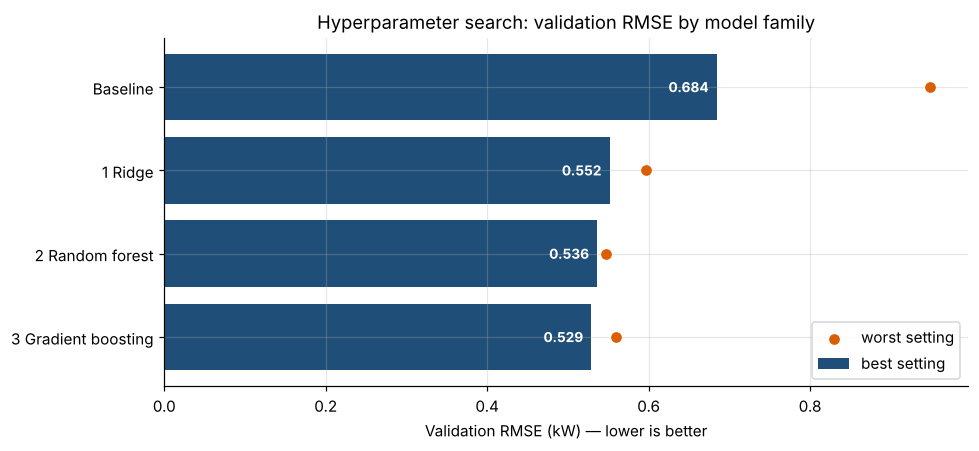

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.2))
plot = res.groupby("experiment")["RMSE"].agg(["min", "max"]).reindex(["Baseline", "1 Ridge", "2 Random forest", "3 Gradient boosting"])
ax.barh(plot.index, plot["min"], color="#1f4e79", label="best setting")
ax.scatter(plot["max"], plot.index, color="#d95f02", zorder=3, label="worst setting")
for y, v in enumerate(plot["min"]): ax.text(v - 0.01, y, f"{v:.3f}", va="center", ha="right", fontsize=9, color="white", fontweight="bold")
ax.invert_yaxis(); ax.set_xlabel("Validation RMSE (kW) — lower is better")
ax.set_title("Hyperparameter search: validation RMSE by model family"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG_DIR / "11_experiment_rmse.png", dpi=300); plt.show()

## 6. Final model: refit on train + validation, score once on test

The winning configuration is refitted on all data before the test period (train + validation, so it also learns the most
recent autumn/winter behaviour) and evaluated **once** on the test set. The naive baselines are scored on the same test hours
for reference.

In [11]:
def make_model(row):
    p = json.loads(row["params"])
    if row["experiment"] == "1 Ridge":
        m = ridge(p["alpha"])
    elif row["experiment"] == "2 Random forest":
        m = RandomForestRegressor(**p, n_jobs=-1, random_state=SEED)
    else:
        m = HistGradientBoostingRegressor(**p, early_stopping=False, random_state=SEED)
    return wrap(m, bool(row["log_target"]))

X_trva, y_trva = pd.concat([X_tr, X_va]), pd.concat([y_tr, y_va])
final_model = make_model(best).fit(X_trva, y_trva)
pred_te = pd.Series(final_model.predict(X_te), index=y_te.index).clip(lower=0)

test_table = pd.DataFrame({
    f"Final model ({best['model']})": scores(y_te, pred_te),
    "Persistence (lag_1)": scores(y_te, X_te["lag_1"]),
    "Same hour yesterday (lag_24)": scores(y_te, X_te["lag_24"]),
    "Same hour last week (lag_168)": scores(y_te, X_te["lag_168"])}).T
display(test_table.round(4))
gain = 1 - test_table.iloc[0]["RMSE"] / test_table.iloc[1:]["RMSE"].min()
print(f"Test RMSE is {gain:.1%} lower than the best naive baseline.")

,MAE,RMSE,R2
Final model (Hist gradient boosting),0.3205,0.4605,0.5723
Persistence (lag_1),0.3730,0.5752,0.3325
Same hour yesterday (lag_24),0.5062,0.7537,-0.1460
Same hour last week (lag_168),0.5594,0.7981,-0.2848


Test RMSE is 19.9% lower than the best naive baseline.


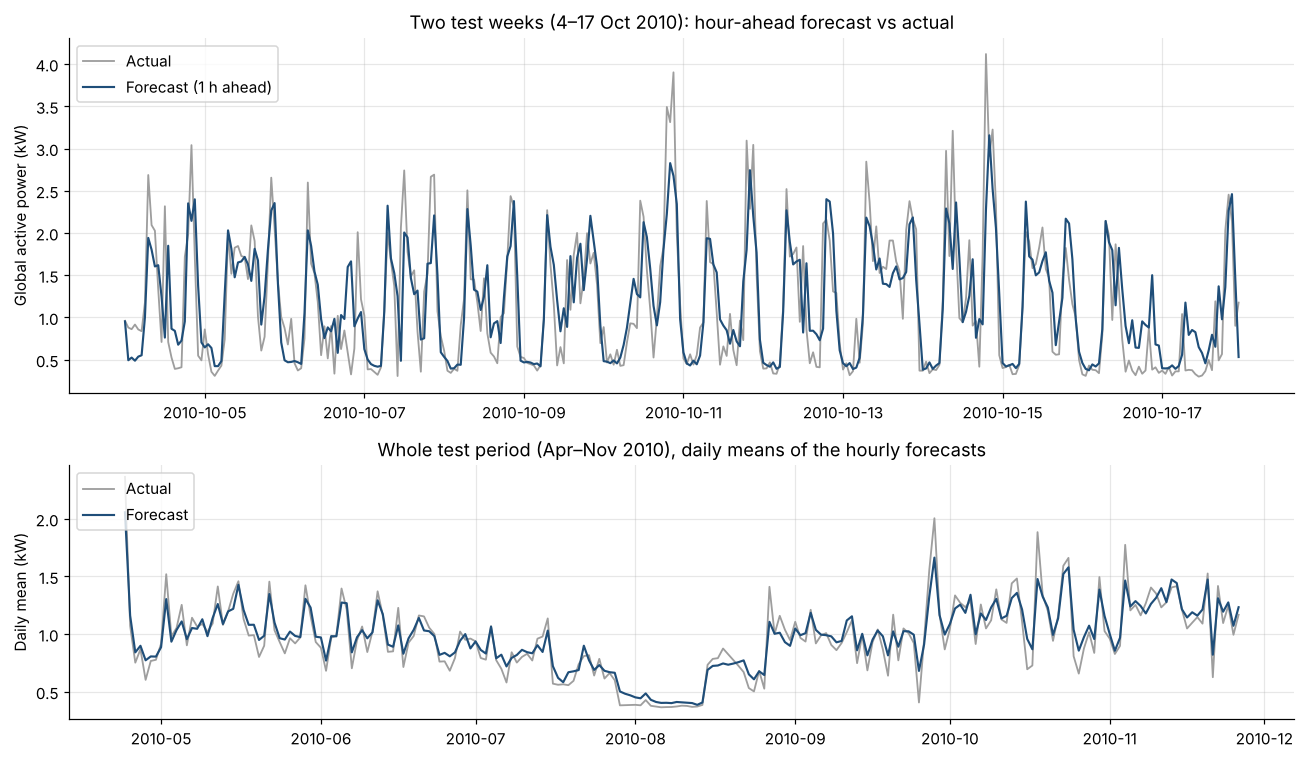

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), gridspec_kw={"height_ratios": [1.4, 1]})
week = slice("2010-10-04", "2010-10-17")
axes[0].plot(y_te[week].index, y_te[week], color="#9e9e9e", lw=1.2, label="Actual")
axes[0].plot(pred_te[week].index, pred_te[week], color="#1f4e79", lw=1.4, label="Forecast (1 h ahead)")
axes[0].set_ylabel("Global active power (kW)"); axes[0].legend(loc="upper left")
axes[0].set_title("Two test weeks (4–17 Oct 2010): hour-ahead forecast vs actual")

daily = pd.DataFrame({"Actual": y_te, "Forecast": pred_te}).resample("D").mean()
axes[1].plot(daily.index, daily["Actual"], color="#9e9e9e", lw=1.2, label="Actual")
axes[1].plot(daily.index, daily["Forecast"], color="#1f4e79", lw=1.4, label="Forecast")
axes[1].set_ylabel("Daily mean (kW)"); axes[1].legend(loc="upper left")
axes[1].set_title("Whole test period (Apr–Nov 2010), daily means of the hourly forecasts")
plt.tight_layout(); plt.savefig(FIG_DIR / "11_test_forecast.png", dpi=300); plt.show()

### Which features matter?

Permutation importance on the test set: how much the test RMSE rises when one feature's values are shuffled. It is
model-agnostic, so it can be read the same way whichever model family won.

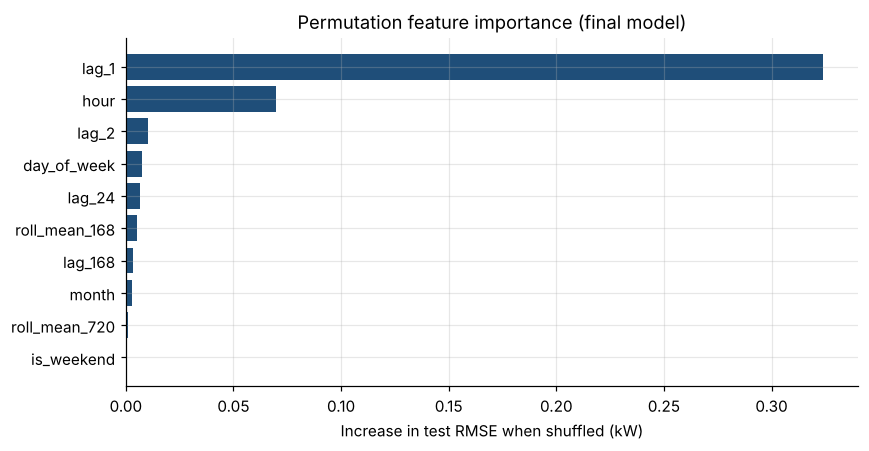

lag_1            0.3240
hour             0.0697
lag_2            0.0103
day_of_week      0.0076
lag_24           0.0065
roll_mean_168    0.0050
lag_168          0.0033
month            0.0030
roll_mean_720    0.0012
is_weekend       0.0000
dtype: float64

In [13]:
pi = permutation_importance(final_model, X_te, y_te, scoring="neg_root_mean_squared_error",
                            n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURE_COLUMNS).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(imp.index, imp.values, color="#1f4e79")
ax.set_xlabel("Increase in test RMSE when shuffled (kW)"); ax.set_title("Permutation feature importance (final model)")
plt.tight_layout(); plt.savefig(FIG_DIR / "11_feature_importance.png", dpi=300); plt.show()
imp.sort_values(ascending=False).round(4)

## 7. Save the model for the prediction script (Task 4)

`scripts/predict.py` loads `models/best_model.joblib` and reads the feature order from `models/feature_columns.json`. Because a
log target is handled inside `TransformedTargetRegressor`, the script must **not** be run with `--log-target`.

In [14]:
joblib.dump(final_model, MODEL_DIR / "best_model.joblib", compress=3)
(MODEL_DIR / "feature_columns.json").write_text(json.dumps(FEATURE_COLUMNS, indent=2))
meta = {
    "model": best["model"], "experiment": best["experiment"], "params": json.loads(best["params"]),
    "log_target_inside_model": bool(best["log_target"]), "target": "Global_active_power (kW), hourly mean, 1 hour ahead",
    "trained_on": f"{X_trva.index.min()} -> {X_trva.index.max()} ({len(X_trva):,} hours)",
    "validation": {k: round(best[k], 4) for k in ["MAE", "RMSE", "R2"]},
    "test": {k: round(v, 4) for k, v in test_table.iloc[0].items()},
    "scikit_learn_version": sklearn.__version__,
}
(MODEL_DIR / "model_metadata.json").write_text(json.dumps(meta, indent=2, default=str))
for f in sorted(MODEL_DIR.iterdir()): print(f"{f}  ({f.stat().st_size/1024:.0f} KB)")
print(json.dumps(meta, indent=2, default=str))

models/best_model.joblib  (299 KB)
models/experiments.csv  (10 KB)
models/feature_columns.json  (0 KB)
models/model_metadata.json  (1 KB)
{
  "model": "Hist gradient boosting",
  "experiment": "3 Gradient boosting",
  "params": {
    "learning_rate": 0.03,
    "max_iter": 200,
    "max_leaf_nodes": 31,
    "l2_regularization": 1.0
  },
  "log_target_inside_model": false,
  "target": "Global_active_power (kW), hourly mean, 1 hour ahead",
  "trained_on": "2007-01-15 17:00:00 -> 2010-04-24 15:00:00 (28,678 hours)",
  "validation": {
    "MAE": 0.3653,
    "RMSE": 0.529,
    "R2": 0.6402
  },
  "test": {
    "MAE": 0.3205,
    "RMSE": 0.4605,
    "R2": 0.5723
  },
  "scikit_learn_version": "1.9.1"
}


## 8. Check the saved model with the real prediction script

This loads `scripts/predict.py` itself and runs its steps C and D — `load_model()` and the recursive `forecast()` — on the
last 31 days of history before a test timestamp. That stands in for step A (fetching from the API), which needs the databases
running. It confirms that (i) the script and the training notebook build identical features, and (ii) the saved model produces
sensible multi-hour forecasts.

In [15]:
spec = importlib.util.spec_from_file_location("predict", "scripts/predict.py")
predict = importlib.util.module_from_spec(spec); spec.loader.exec_module(predict)

# (i) identical features: the script's make_features() vs the training table, on 200 random test hours
rng = np.random.default_rng(SEED)
for ts in rng.choice(X_te.index, 200, replace=False):
    ts = pd.Timestamp(ts)
    script_feats = pd.Series(predict.make_features(hourly[hourly.index < ts], ts))[FEATURE_COLUMNS]
    assert np.allclose(script_feats.astype(float).values, X_te.loc[ts].astype(float).values), ts
print("make_features() in scripts/predict.py matches the training features on 200 test hours")

# (ii) end-to-end C + D on a test-period history window
model, cols = predict.load_model(MODEL_DIR / "best_model.joblib", MODEL_DIR / "feature_columns.json")
cutoff = pd.Timestamp("2010-11-01 00:00")
history = hourly[(hourly.index >= cutoff - pd.Timedelta(days=predict.HISTORY_DAYS)) & (hourly.index < cutoff)]
fc = predict.forecast(model, cols, history, steps=24, log_target=False)
cmp = pd.DataFrame({"forecast_kW": fc, "actual_kW": hourly.reindex(fc.index)})
print(f"24-hour recursive forecast from {cutoff}: MAE = {mean_absolute_error(cmp.actual_kW, cmp.forecast_kW):.3f} kW")
cmp.round(3).head(12)

make_features() in scripts/predict.py matches the training features on 200 test hours
[C] loaded HistGradientBoostingRegressor from models/best_model.joblib (10 features)
24-hour recursive forecast from 2010-11-01 00:00:00: MAE = 0.630 kW


,forecast_kW,actual_kW
2010-11-01 00:00:00,1.414,1.319
2010-11-01 01:00:00,1.024,1.480
2010-11-01 02:00:00,0.630,1.286
2010-11-01 03:00:00,0.525,1.065
2010-11-01 04:00:00,0.480,0.327
2010-11-01 05:00:00,0.503,0.450
2010-11-01 06:00:00,0.938,0.405
2010-11-01 07:00:00,1.676,0.385
2010-11-01 08:00:00,1.697,0.318
2010-11-01 09:00:00,1.512,1.198


## 9. Conclusion

The experiment table above compares three tuned model families against three naive baselines on the validation set, and the
best configuration is reported once on the test set. The model is saved in `models/` together with its feature list, metadata
and the full experiment log, and the check in section 8 shows that `scripts/predict.py` can load it and forecast with the same
features used in training.

**Limitations.** The model forecasts hourly *means*. Short minute-level spikes are averaged away and cannot be predicted from
history alone. Multi-hour forecasts are recursive, so errors compound with the horizon. Only one household is modelled, so the
results describe this home's habits rather than demand in general.